In [1]:
import pandas as pd

df = pd.read_parquet("SDWPF_dataset/sdwpf_full/sdwpf_2001_2112_full.parquet")
print(df.shape)  
df.info()
df.head()

(11361190, 18)
<class 'pandas.DataFrame'>
RangeIndex: 11361190 entries, 0 to 11361189
Data columns (total 18 columns):
 #   Column   Dtype         
---  ------   -----         
 0   TurbID   int64         
 1   Tmstamp  datetime64[ns]
 2   Wspd     float64       
 3   Wdir     float64       
 4   Etmp     float64       
 5   Itmp     float64       
 6   Ndir     float64       
 7   Pab1     float64       
 8   Pab2     float64       
 9   Pab3     float64       
 10  Prtv     float64       
 11  T2m      float32       
 12  Sp       float32       
 13  RelH     float32       
 14  Wspd_w   float64       
 15  Wdir_w   float64       
 16  Tp       float32       
 17  Patv     float64       
dtypes: datetime64[ns](1), float32(4), float64(12), int64(1)
memory usage: 1.4 GB


,TurbID,Tmstamp,Wspd,Wdir,Etmp,Itmp,Ndir,Pab1,Pab2,Pab3,Prtv,T2m,Sp,RelH,Wspd_w,Wdir_w,Tp,Patv
0,57,2020-01-03 04:25:00,7.935,0.055,2.185,23.415,236.59,-0.840,-0.840,-0.845,29.680,-12.312683,85893.515625,0.529154,5.191925,52.389540,0.0,976.925
1,57,2020-01-03 04:55:00,6.425,-1.860,2.945,23.550,236.59,-0.610,-0.605,-0.610,14.480,-12.312683,85893.515625,0.529154,5.191925,52.389540,0.0,610.830
2,57,2020-01-03 05:25:00,5.945,-1.635,3.720,23.350,236.59,-0.435,-0.435,-0.435,15.270,-11.709015,85836.429688,0.516070,5.563238,56.420248,0.0,483.850
3,57,2020-01-03 05:55:00,6.290,1.220,4.385,23.285,236.59,-0.510,-0.510,-0.510,19.030,-11.709015,85836.429688,0.516070,5.563238,56.420248,0.0,536.970
4,57,2020-01-03 06:25:00,5.650,3.790,4.945,23.265,243.84,-0.355,-0.355,-0.355,9.795,-10.475830,85820.765625,0.515158,6.000677,55.780818,0.0,431.700


In [2]:
# 1) Koliko vrijednosti nedostaje po koloni
print(df.isna().sum())

# 2) Brojke za mejl: redovi s bar jednom praznom vrijednošću, nule, "nepoznate"
n = len(df)
missing = df.isna().any(axis=1).sum()
zero = (df["Patv"] == 0).sum()
unknown = (
    ((df["Patv"] <= 0) & (df["Wspd"] > 2.5))
    | (df[["Pab1", "Pab2", "Pab3"]] > 89).any(axis=1)
).sum()

for naziv, broj in [("nedostajuće", missing), ("nule", zero), ("nepoznate", unknown)]:
    print(f"{naziv}: {broj:,} ({broj / n:.2%})")

# 3) Razmak između zapisa jedne turbine i broj turbina
t = df[df["TurbID"] == 57].sort_values("Tmstamp")
print(t["Tmstamp"].diff().value_counts().head(5))
print("Broj turbina:", df["TurbID"].nunique())
print("Period:", df["Tmstamp"].min(), "->", df["Tmstamp"].max())

TurbID          0
Tmstamp         0
Wspd       496998
Wdir       496998
Etmp       496998
Itmp       496998
Ndir       496998
Pab1       496998
Pab2       496998
Pab3       496998
Prtv       496998
T2m          4288
Sp           4288
RelH         4288
Wspd_w       4288
Wdir_w       4288
Tp           4288
Patv       496998
dtype: int64
nedostajuće: 496,998 (4.37%)
nule: 273,846 (2.41%)
nepoznate: 2,583,959 (22.74%)
Tmstamp
0 days 00:10:00     52560
0 days 00:15:00     32222
30 days 00:15:00        1
0 days 08:15:00         1
Name: count, dtype: int64
Broj turbina: 134
Period: 2020-01-01 00:10:00 -> 2022-01-01 00:10:00


In [3]:
# Sortiraj po turbini i vremenu, inače su razmaci besmisleni
df = df.sort_values(["TurbID", "Tmstamp"]).reset_index(drop=True)

# Razmaci između uzastopnih zapisa unutar iste turbine
razmak = df.groupby("TurbID")["Tmstamp"].diff()
pd.set_option("display.max_rows", 30)
print(razmak.value_counts().head(15))

# Koliko redova ima svaka turbina (idealno 105.120 za 10-min korak)
print(df.groupby("TurbID").size().describe())

# Duplikati po turbini i vremenu
print("Duplikati:", df.duplicated(["TurbID", "Tmstamp"]).sum())

Tmstamp
0 days 00:10:00     7043040
0 days 00:15:00     4317748
30 days 00:15:00        134
0 days 08:15:00         134
Name: count, dtype: int64
count      134.0
mean     84785.0
std          0.0
min      84785.0
25%      84785.0
50%      84785.0
75%      84785.0
max      84785.0
dtype: float64
Duplikati: 0


In [4]:
# Jedna turbina je dovoljna: razmaci su isti za sve
t = df[df["TurbID"] == df["TurbID"].iloc[0]].copy()
t["razmak"] = t["Tmstamp"].diff()

# Gdje su velike rupe
print(t[t["razmak"] > pd.Timedelta("1h")][["Tmstamp", "razmak"]])

# U kojem periodu je korak 10 min, a u kojem 15 min
for korak in ["10min", "15min"]:
    d = t.loc[t["razmak"] == pd.Timedelta(korak), "Tmstamp"]
    print(f"Korak {korak}: od {d.min()} do {d.max()}")

                  Tmstamp           razmak
8736  2020-05-01 00:10:00 30 days 00:15:00
32224 2021-01-01 00:10:00  0 days 08:15:00
Korak 10min: od 2021-01-01 00:20:00 do 2022-01-01 00:10:00
Korak 15min: od 2020-01-01 00:25:00 do 2020-12-31 15:55:00


In [5]:
# Podijeli vrijeme na sate (bez učenja iz podataka, pa nema curenja)
df["sat"] = df["Tmstamp"].dt.floor("h")

# Srednja vrijednost svih mjerenja unutar sata za svaku turbinu
satni = (
    df.drop(columns="Tmstamp")
      .groupby(["TurbID", "sat"], as_index=False)
      .mean()
)

print(satni.shape)
satni.head()

(2253478, 18)


,TurbID,sat,Wspd,Wdir,Etmp,Itmp,Ndir,Pab1,Pab2,Pab3,Prtv,T2m,Sp,RelH,Wspd_w,Wdir_w,Tp,Patv
0,1,2020-01-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,2020-01-01 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,2020-01-01 02:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1,2020-01-01 03:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1,2020-01-01 04:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
# Koliko satnih redova nema metu
print("Satni redovi bez mete:", satni["Patv"].isna().sum(),
      f"({satni['Patv'].isna().mean():.2%})")

# Ima li redova gdje je meta prazna, a neka mjerenja nisu (i obrnuto)?
scada = ["Wspd", "Wdir", "Etmp", "Itmp", "Ndir", "Pab1", "Pab2", "Pab3", "Prtv"]
print("Meta prazna, a Wspd nije:", (satni["Patv"].isna() & satni["Wspd"].notna()).sum())
print("Meta tu, a Wspd prazan:  ", (satni["Patv"].notna() & satni["Wspd"].isna()).sum())

# Udio praznih po mjesecu: vidi se da li su kvarovi grupirani u vremenu
satni["mjesec"] = satni["sat"].dt.to_period("M")
print(satni.groupby("mjesec")["Patv"].apply(lambda s: s.isna().mean()).round(3))

# 10 turbina s najviše praznina
print(satni.groupby("TurbID")["Patv"].apply(lambda s: s.isna().mean())
      .sort_values(ascending=False).head(10).round(3))

Satni redovi bez mete: 89330 (3.96%)
Meta prazna, a Wspd nije: 0
Meta tu, a Wspd prazan:   0
mjesec
2020-01    0.218
2020-02    0.008
2020-03    0.042
2020-05    0.001
2020-06    0.006
2020-07    0.054
2020-08    0.000
2020-09    0.001
2020-10    0.000
2020-11    0.003
2020-12    0.000
2021-01    0.226
2021-02    0.000
2021-03    0.001
2021-04    0.002
2021-05    0.007
2021-06    0.000
2021-07    0.252
2021-08    0.002
2021-09    0.003
2021-10    0.000
2021-11    0.073
2021-12    0.000
2022-01    1.000
Freq: M, Name: Patv, dtype: float64
TurbID
83     0.129
126    0.075
52     0.058
127    0.051
90     0.046
18     0.045
67     0.045
21     0.045
36     0.045
80     0.044
Name: Patv, dtype: float64


In [7]:
pd.set_option("display.max_rows", 100)  # inače pandas skraćuje ispis

# Za svaki sat: koji udio turbina nema podatak
po_satu = satni.groupby("sat")["Patv"].apply(lambda s: s.isna().mean())
print("Sati u kojima nedostaje više od 90% turbina:", (po_satu > 0.9).sum(), "od", len(po_satu))
print("Sati u kojima nedostaje 0 turbina:", (po_satu == 0).sum())

# Koji su dani pogođeni i koliko sati svakog dana
dani = po_satu[po_satu > 0.9].index.normalize().value_counts().sort_index()
print(dani)

# Udio praznih po mjesecu, samo zadnjih 6 mjeseci (da vidimo test period)
print(satni.groupby("mjesec")["Patv"].apply(lambda s: s.isna().mean()).round(3).tail(6))

Sati u kojima nedostaje više od 90% turbina: 524 od 16817
Sati u kojima nedostaje 0 turbina: 12913
sat
2020-01-01    24
2020-01-02    24
2020-01-16    14
2020-01-17    12
2020-03-31     8
2020-07-04     8
2020-07-05    24
2020-07-06     5
2021-01-15    24
2021-01-16    24
2021-01-17    24
2021-01-18    24
2021-01-19    24
2021-01-20    24
2021-01-21    24
2021-07-06     7
2021-07-07    24
2021-07-08    24
2021-07-09    24
2021-07-10    24
2021-07-11    24
2021-07-12    24
2021-07-13    24
2021-07-14    10
2021-11-02    11
2021-11-03    24
2021-11-04     3
2021-11-08    13
2022-01-01     1
Name: count, dtype: int64
mjesec
2021-08    0.002
2021-09    0.003
2021-10    0.000
2021-11    0.073
2021-12    0.000
2022-01    1.000
Freq: M, Name: Patv, dtype: float64


In [8]:
# Izbaci pomoćnu kolonu i jedini sat iz 2022. (potpuno prazan)
satni = satni.drop(columns="mjesec")
satni = satni[satni["sat"] < "2022-01-01"]

# Hronološka podjela: sve do kraja avgusta 2021. je razvoj, dalje je završni test
granica = pd.Timestamp("2021-09-01")
razvoj = satni[satni["sat"] < granica].copy()
test = satni[satni["sat"] >= granica].copy()

print("Razvoj:", len(razvoj), "| Test:", len(test), f"| Udio testa: {len(test)/len(satni):.1%}")

# Sačuvaj odvojeno, test se otvara samo za završnu evaluaciju
razvoj.to_parquet("razvoj.parquet")
test.to_parquet("test_ne_diraj.parquet")

Razvoj: 1860992 | Test: 392352 | Udio testa: 17.4%


In [9]:
nazivi = {
    "TurbID": "turbina_id", "sat": "sat",
    "Wspd": "brzina_vjetra_turbina", "Wdir": "ugao_vjetar_turbina",
    "Etmp": "temp_vanjska", "Itmp": "temp_unutrasnja",
    "Ndir": "smjer_kucista",
    "Pab1": "ugao_lopatice_1", "Pab2": "ugao_lopatice_2", "Pab3": "ugao_lopatice_3",
    "Prtv": "reaktivna_snaga",
    "T2m": "temp_zraka_2m", "Sp": "pritisak", "RelH": "vlaznost",
    "Wspd_w": "brzina_vjetra_10m", "Wdir_w": "smjer_vjetra_10m",
    "Tp": "padavine", "Patv": "aktivna_snaga",
}
razvoj = razvoj.rename(columns=nazivi)
test = test.rename(columns=nazivi)   # ista imena, ali test ne analiziramo

# Opisna statistika samo na razvojnom skupu
brojcane = razvoj.drop(columns=["turbina_id", "sat"])
stat = brojcane.describe().T            # count, mean, std, min, 25%, 50%, 75%, max
stat["asimetrija"] = brojcane.skew()
stat["zaobljenost"] = brojcane.kurt()
stat.round(3)

,count,mean,std,min,25%,50%,75%,max,asimetrija,zaobljenost
brzina_vjetra_turbina,1779130.0,5.010,3.406,0.000,2.239,4.278,6.965,52.657,1.082,1.244
ugao_vjetar_turbina,1779130.0,0.746,26.549,-404.149,-2.610,-0.223,2.162,316.398,0.271,11.072
temp_vanjska,1779130.0,33.400,74.678,-273.170,9.485,21.210,31.168,394.330,4.151,17.906
temp_unutrasnja,1779130.0,25.550,17.714,-273.170,17.425,26.896,35.562,182.900,-8.512,126.767
smjer_kucista,1779130.0,177.034,169.615,-1083.700,52.177,186.627,312.050,700.630,-0.462,0.267
ugao_lopatice_1,1779130.0,27.014,36.645,-10.000,0.020,2.421,64.519,99.980,0.907,-0.977
ugao_lopatice_2,1779130.0,27.002,36.635,-10.000,0.020,2.418,64.440,99.665,0.907,-0.976
ugao_lopatice_3,1779130.0,26.999,36.632,-6.165,0.020,2.416,64.416,99.980,0.907,-0.976
reaktivna_snaga,1779130.0,-8.230,62.118,-587.848,-26.998,-0.300,0.529,405.182,-0.556,5.640
temp_zraka_2m,1859920.0,10.334,13.890,-22.302,-1.247,11.982,22.109,37.662,-0.238,-1.062


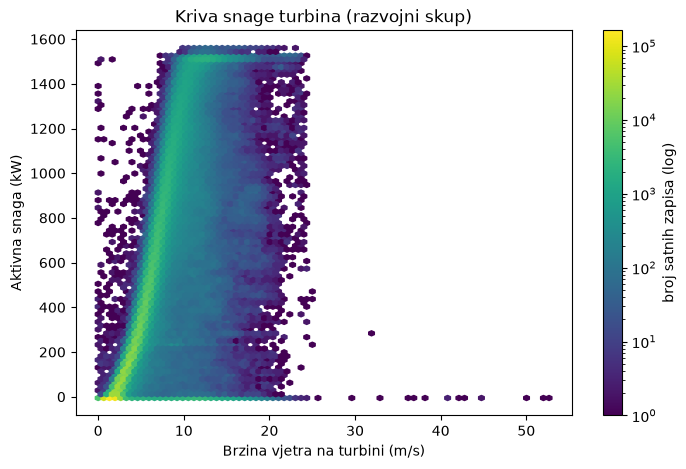

In [10]:
import matplotlib.pyplot as plt

d = razvoj.dropna(subset=["brzina_vjetra_turbina", "aktivna_snaga"])

plt.figure(figsize=(8, 5))
plt.hexbin(d["brzina_vjetra_turbina"], d["aktivna_snaga"],
           gridsize=80, bins="log", cmap="viridis")  # log skala boje: i rijetke tačke se vide
plt.colorbar(label="broj satnih zapisa (log)")
plt.xlabel("Brzina vjetra na turbini (m/s)")
plt.ylabel("Aktivna snaga (kW)")
plt.title("Kriva snage turbina (razvojni skup)")
plt.show()

In [11]:
# Pravila "fizički nemoguće" po dokumentaciji i zdravom razumu
pravila = {
    "temp_vanjska izvan [-50, 60]":        (razvoj["temp_vanjska"] < -50) | (razvoj["temp_vanjska"] > 60),
    "temp_unutrasnja izvan [-50, 100]":    (razvoj["temp_unutrasnja"] < -50) | (razvoj["temp_unutrasnja"] > 100),
    "ugao_vjetar_turbina izvan [-180,180]":(razvoj["ugao_vjetar_turbina"].abs() > 180),
    "smjer_kucista izvan [-720, 720]":     (razvoj["smjer_kucista"].abs() > 720),
    "brzina_vjetra_turbina > 40":          (razvoj["brzina_vjetra_turbina"] > 40),
    "aktivna_snaga < 0":                   (razvoj["aktivna_snaga"] < 0),
    "aktivna_snaga > 1500":                (razvoj["aktivna_snaga"] > 1500),
}
for naziv, maska in pravila.items():
    print(f"{naziv}: {maska.sum():,} ({maska.mean():.3%})")

# IQR ekstremi po koloni (Q1 - 1.5*IQR, Q3 + 1.5*IQR)
print("\nIQR ekstremi:")
for k in brojcane.columns:
    q1, q3 = razvoj[k].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((razvoj[k] < q1 - 1.5*iqr) | (razvoj[k] > q3 + 1.5*iqr)).sum()
    print(f"{k}: {n:,} ({n/razvoj[k].notna().sum():.2%})")

temp_vanjska izvan [-50, 60]: 78,669 (4.227%)
temp_unutrasnja izvan [-50, 100]: 5,709 (0.307%)
ugao_vjetar_turbina izvan [-180,180]: 11 (0.001%)
smjer_kucista izvan [-720, 720]: 25 (0.001%)
brzina_vjetra_turbina > 40: 10 (0.001%)
aktivna_snaga < 0: 375,704 (20.188%)
aktivna_snaga > 1500: 24,358 (1.309%)

IQR ekstremi:
brzina_vjetra_turbina: 28,854 (1.62%)
ugao_vjetar_turbina: 424,004 (23.83%)
temp_vanjska: 78,848 (4.43%)
temp_unutrasnja: 6,558 (0.37%)
smjer_kucista: 12,080 (0.68%)
ugao_lopatice_1: 0 (0.00%)
ugao_lopatice_2: 0 (0.00%)
ugao_lopatice_3: 0 (0.00%)
reaktivna_snaga: 418,620 (23.53%)
temp_zraka_2m: 0 (0.00%)
pritisak: 804 (0.04%)
vlaznost: 18,358 (0.99%)
brzina_vjetra_10m: 29,748 (1.60%)
smjer_vjetra_10m: 0 (0.00%)
padavine: 128,640 (6.92%)
aktivna_snaga: 44,469 (2.50%)


In [12]:
losi = razvoj[(razvoj["temp_vanjska"] < -50) | (razvoj["temp_vanjska"] > 60)]

# Koje se vrijednosti ponavljaju: šifra za grešku ili raspršeno?
print(losi["temp_vanjska"].round(1).value_counts().head(10))

# Šta radi turbina u tim redovima?
print(losi["aktivna_snaga"].describe())

# Da li su vezani za pojedine turbine ili mjesece?
print(losi.groupby("turbina_id").size().sort_values(ascending=False).head(10))
print(losi["sat"].dt.to_period("M").value_counts().sort_index())

temp_vanjska
 394.0    19785
 392.5    11716
 393.2     8028
 393.7     8017
 324.6     7947
 394.3     7865
 393.3     3427
 393.0     2585
 392.7     2428
-257.1      104
Name: count, dtype: int64
count    78669.000000
mean       332.012510
std        414.537518
min         -3.933750
25%          0.000000
50%        154.316250
75%        522.262500
max       1559.733333
Name: aktivna_snaga, dtype: float64
turbina_id
25     11782
24     11709
61      8060
38      8057
68      8049
67      7975
121     7954
122     3417
40      2604
18      2399
dtype: int64
sat
2020-01    4062
2020-02    6499
2020-03    6541
2020-05    7032
2020-06    6311
2020-07    5734
2020-08    5398
2020-09    5438
2020-10    5894
2020-11    5490
2020-12    5571
2021-01    3300
2021-02    1477
2021-03    2415
2021-04    2540
2021-05    2540
2021-06    1836
2021-07     310
2021-08     281
Freq: M, Name: count, dtype: int64
